# Dark Pattern Detector for E-Commerce Websites

## 1. Problem Statement and Overview

#### Problem Statement

Dark patterns are deceptive interface techniques that influence users into making decisions they may not otherwise make. On e-commerce websites, these techniques may appear through manipulative language such as:

- **Urgency:** “Hurry! Offer ends in 5 minutes.”
- **Scarcity:** “Only 2 items remaining.”
- **Social Proof:** “17 shoppers have this item in their cart.”
- **Confirmshaming:** “No thanks, I don’t want to save 20%.”
- **Forced Continuity:** “Your subscription will automatically renew unless cancelled.”

Manually reviewing thousands of e-commerce messages is time-consuming and difficult to scale. Therefore, this project develops a Natural Language Processing system that automatically screens short interface text for potential dark-pattern language.

#### Project Objective

The primary objective is to train and compare multiple binary text-classification models that predict whether a given e-commerce message is:

- **Not Dark Pattern — 0**
- **Potential Dark Pattern — 1**

The models evaluated in this project are:

1. TF-IDF with classical machine-learning algorithms
2. Word2Vec with a Bidirectional LSTM
3. Fine-tuned DistilBERT

The best-performing model is selected using validation performance and evaluated once on a held-out test set.

#### Deployment Extension

The trained model performs **binary classification only**. In the deployed Streamlit application, an additional transparent rule-based layer provides a likely category such as Urgency, Scarcity, Social Proof or Confirmshaming.

The category is an explanatory suggestion and not the output of a separately trained multiclass model.

#### Scope and Limitation

This project detects language associated with potential dark patterns. Text alone cannot verify whether a claim is factually false, intentionally deceptive or supported by genuine circumstances. Therefore, the system is designed as a **risk-screening tool**, not as final proof that a website uses a dark pattern.

## Table of Contents

1. Problem Statement and Overview
2. Importing Libraries
3. Load the Data
4. Exploratory Data Analysis
5. Domain-Specific Cleaning, Duplicate Control and Preprocessing
6. Leakage-Safe Train, Validation and Test Split
7. Tier 1 — Classical ML: TF‑IDF + Logistic Regression / Linear SVM

   * 7.1 Classical Model Selection and Tuning
   * 7.2 Interpretability Check using LIME

8. Tier 2 — Word2Vec + BiLSTM
9. Tier 3 — DistilBERT (Transformer)
10. Final Diagnostics and Saving Deployment Artifacts
11. Inference Function
12. Conclusion and Deployment

    * 11.1 Recommended Next Extension

## 2. Importing Libraries

In [1]:
import os
import re
import html
import random
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, 
                             roc_auc_score, roc_curve, precision_recall_curve, average_precision_score)
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_class_weight

from gensim.models import Word2Vec
from lime.lime_text import LimeTextExplainer

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Embedding, Bidirectional, LSTM, Dense, Dropout, Conv1D, GlobalMaxPooling1D)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

import torch
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer, EarlyStoppingCallback)

import json
import pickle

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print('Python-ready. TensorFlow:', tf.__version__, '| Torch:', torch.__version__)

Python-ready. TensorFlow: 2.21.0 | Torch: 2.13.0+cpu


## 3. Load the Data

We’ll use two Kaggle files:

- **patterns.csv** → ~400 rows. Each row has a *Pattern String* plus metadata.  
  - Key column: *Deceptive* → *"Not Dark"* or a dark‑pattern category (e.g. *Urgency*, *Scarcity*, *Social Proof*).  
  - This serves both as a category label and a binary flag (*Not Dark* = 0, anything else = 1).

- **pattern_classifications.csv** → ~2,700 rows. Each row has a *Pattern String* and a binary *classification* column (0/1).  
  - No category labels here.

We’ll load both files and merge them into one table with three columns:  
- `text` → the pattern string  
- `label` → binary (0/1)  
- `category` → filled only when available


In [2]:
patterns_csv = 'patterns.csv'                           # category-labelled file (~400 rows)
classifications_csv = 'pattern_classifications.csv'     # large binary-labelled file (~2700 rows)

# Manual overrides — leaving as None to auto-detect
text_col_override = None
label_col_override = None              # binary label column inside CLASSIFICATIONS_CSV
category_label_col_override = None     # e.g. 'Deceptive' inside PATTERNS_CSV
category_col_override = None           # e.g. 'Pattern Category' inside PATTERNS_CSV

def find_col(df, override, candidates):
    if override is not None:
        if override not in df.columns:
            raise ValueError(f"Override column '{override}' not found. Available columns: {df.columns.tolist()}")
        return override
    for candidate in candidates:
        for col in df.columns:
            if col.strip().lower() == candidate.lower():
                return col
    return None

patterns_raw = pd.read_csv(patterns_csv)
class_raw = pd.read_csv(classifications_csv)
print("patterns.csv columns:", patterns_raw.columns.tolist(), "| shape:", patterns_raw.shape)
print("pattern_classifications.csv columns:", class_raw.columns.tolist(), "| shape:", class_raw.shape)

# patterns.csv: text + a category column that also implies the binary label
p_text_col = find_col(patterns_raw, text_col_override,['text', 'pattern string', 'pattern_string', 'pattern', 'content'])
p_category_label_col = find_col(patterns_raw, category_label_col_override,['deceptive', 'is_dark', 'dark_pattern'])
p_category_col = find_col(patterns_raw, category_col_override,['pattern category', 'pattern_category', 'category', 'type'])
assert p_text_col is not None, f"Could not find the text column in {PATTERNS_CSV} — set text_col_override."
assert p_category_label_col is not None, f"Could not find the Deceptive/category-label column in {PATTERNS_CSV} — set category_label_col_overrideE."

patterns_part = pd.DataFrame({'text': patterns_raw[p_text_col],
                              'raw_label': patterns_raw[p_category_label_col],
                              'category': patterns_raw[p_category_col] if p_category_col else np.nan})

# Here 'Not Dark' is the only negative value; every other Deceptive value is a dark-pattern category.

patterns_part['label'] = np.where(patterns_part['raw_label'].astype(str).str.strip().str.lower() == 'not dark', 0, 1)

# pattern_classifications.csv: text + a ready-made binary label
c_text_col = find_col(class_raw, text_col_override, ['text', 'pattern string', 'pattern_string', 'pattern', 'content'])
c_label_col = find_col(class_raw, label_col_override, ['classification', 'label', 'is_dark', 'dark_pattern', 'target'])

assert c_text_col is not None, f"Could not find the text column in {CLASSIFICATIONS_CSV} — set text_col_override."
assert c_label_col is not None, f"Could not find the classification/label column in {CLASSIFICATIONS_CSV} — set label_col_override."

class_part = pd.DataFrame({'text': class_raw[c_text_col],
                           'raw_label': class_raw[c_label_col],
                           'category': np.nan})
class_part['label'] = class_part['raw_label']

# patterns.csv rows go first: when the same text string exists in both files, we later keep the richer, category-labelled version rather than the category-less one from the classification file.
raw_df = pd.concat([patterns_part, class_part], ignore_index=True)
print("Combined rows before cleaning:", len(raw_df))
raw_df.head()

patterns.csv columns: ['Pattern String', 'Comment', 'Pattern Category', 'Pattern Type', 'Where in website?', 'Deceptive', 'Website Page', 'Industry Type'] | shape: (416, 8)
pattern_classifications.csv columns: ['Pattern String', 'classification'] | shape: (2700, 2)
Combined rows before cleaning: 3116


,text,raw_label,category,label
0,Your order is reserved for 07:28 minutes!,Urgency,Urgency,1.0
1,Someone in Bacchus Marsh bought a Noosa Basics...,Not Dark,Social Proof,0.0
2,Only 4 left,Not Dark,Scarcity,0.0
3,0011Days:0088Hours:4411Minutes:21125445Seconds,Urgency,Urgency,1.0
4,NaN,Urgency,Urgency,1.0


In [3]:
raw_df = raw_df.dropna(subset=['text']).copy()
raw_df['text'] = raw_df['text'].astype(str).str.strip()
raw_df = raw_df[raw_df['text'].ne('')].copy()

POSITIVE_LABELS = {'dark', 'dark pattern', 'dark_pattern', 'true', '1', 'yes'}
NEGATIVE_LABELS = {'not dark', 'not dark pattern', 'non-dark', 'non dark', 'false', '0', 'no', 'normal'}

def normalize_binary_label(value):
    if pd.isna(value):
        return np.nan
    if isinstance(value, (bool, np.bool_)):
        return int(value)
    if isinstance(value, (int, np.integer)) and value in (0, 1):
        return int(value)
    if isinstance(value, float) and value in (0.0, 1.0):
        return int(value)
    token = str(value).strip().lower()
    if token in POSITIVE_LABELS:
        return 1
    if token in NEGATIVE_LABELS:
        return 0
    return np.nan

raw_df['label'] = raw_df['label'].apply(normalize_binary_label)
unknown_labels = raw_df[raw_df['label'].isna()]['raw_label'].value_counts(dropna=False)
if len(unknown_labels):
    print('WARNING — unmapped labels were NOT silently converted to 0:')
    print(unknown_labels.head(20))
    print('Review POSITIVE_LABELS/NEGATIVE_LABELS if any of these are legitimate classes.')

raw_df = raw_df.dropna(subset=['label']).copy()
raw_df['label'] = raw_df['label'].astype(int)

# Some Pattern Strings appear in BOTH source files. Keeping the first occurrence means the
# patterns.csv version (with its category) wins over the category-less duplicate.
before = len(raw_df)
df = raw_df.drop_duplicates(subset='text', keep='first').reset_index(drop=True)
df = df[['text', 'label', 'category', 'raw_label']]
print(f'Removed {before - len(df)} exact-duplicate text rows shared between the two source files.')
print('Rows after text/label validation:', len(df))
df.head()

WARNING — unmapped labels were NOT silently converted to 0:
raw_label
NaN    1
Name: count, dtype: int64
Review POSITIVE_LABELS/NEGATIVE_LABELS if any of these are legitimate classes.
Removed 653 exact-duplicate text rows shared between the two source files.
Rows after text/label validation: 2087


,text,label,category,raw_label
0,Your order is reserved for 07:28 minutes!,1,Urgency,Urgency
1,Someone in Bacchus Marsh bought a Noosa Basics...,0,Social Proof,Not Dark
2,Only 4 left,0,Scarcity,Not Dark
3,0011Days:0088Hours:4411Minutes:21125445Seconds,1,Urgency,Urgency
4,Hurry! Only 1 left!,0,Scarcity,Not Dark


## 4. Exploratory Data Analysis

In [4]:
print('Missing values:\n', df.isnull().sum())
print('\nExact duplicate texts:', df['text'].duplicated().sum())
print('\nClass counts (0=Not Dark, 1=Dark):\n', df['label'].value_counts())
print('\nClass proportions:\n', df['label'].value_counts(normalize=True).round(4))

Missing values:
 text            0
label           0
category     1815
raw_label       0
dtype: int64

Exact duplicate texts: 0

Class counts (0=Not Dark, 1=Dark):
 label
0    1605
1     482
Name: count, dtype: int64

Class proportions:
 label
0    0.769
1    0.231
Name: proportion, dtype: float64


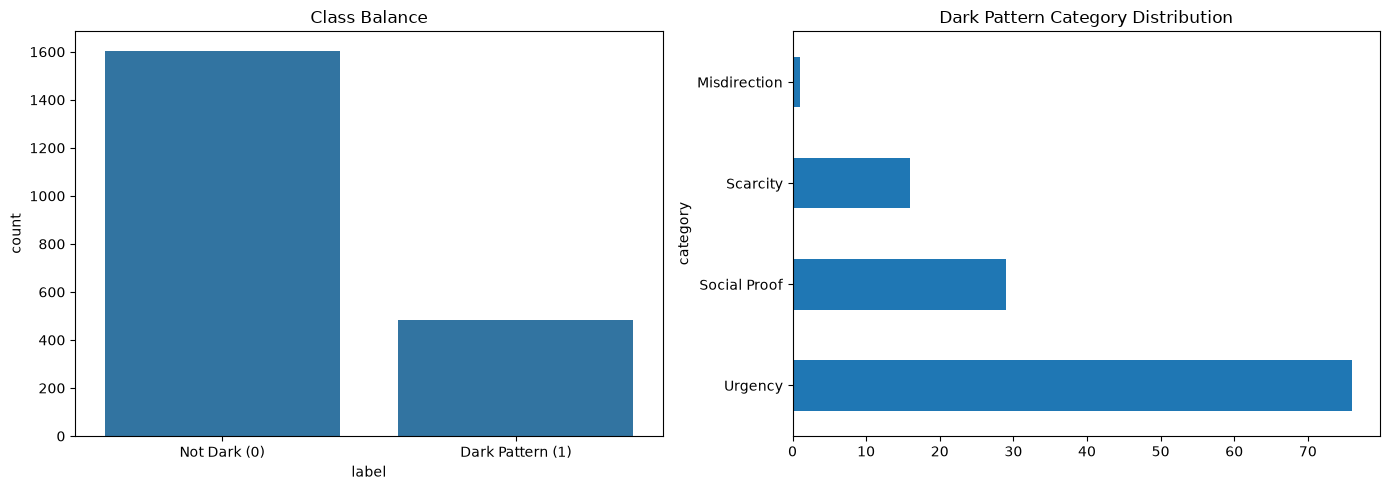

In [5]:
fig, axes = plt.subplots(1, 2 if 'category' in df.columns else 1, figsize=(14, 5))
ax0 = axes[0] if 'category' in df.columns else axes
sns.countplot(x='label', data=df, ax=ax0)
ax0.set_xticklabels(['Not Dark (0)', 'Dark Pattern (1)'])
ax0.set_title('Class Balance')

if 'category' in df.columns:
    df[df['label']==1]['category'].value_counts().plot(kind='barh', ax=axes[1])
    axes[1].set_title('Dark Pattern Category Distribution')
plt.tight_layout()
plt.show()

**Observation:** dark-pattern datasets built this way are typically **imbalanced** — non-dark-pattern text (ordinary product descriptions, policies, etc.) usually outnumbers dark-pattern text, since negative examples are added afterwards by scraping ordinary page content. We check the exact ratio above and handle it explicitly later with class weighting, rather than pretending it isn't there.

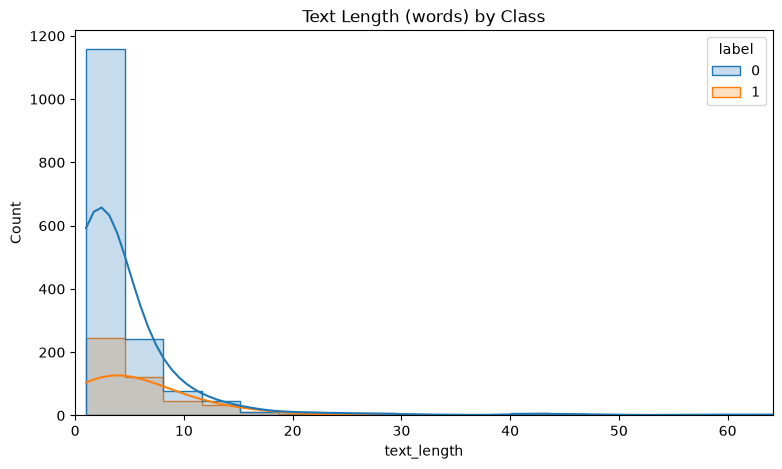

        count      mean        std  min  25%  50%  75%    max
label                                                        
0      1605.0  5.403115  10.870703  1.0  1.0  2.0  5.0  143.0
1       482.0  7.514523  12.444170  1.0  2.0  4.0  8.0  106.0


In [6]:
df['text_length'] = df['text'].apply(lambda x: len(str(x).split()))
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x='text_length', hue='label', bins=40, kde=True, element='step')
plt.title('Text Length (words) by Class')
plt.xlim(0, df['text_length'].quantile(0.99))
plt.show()
print(df.groupby('label')['text_length'].describe())

**A domain-specific preprocessing decision, upfront:** unlike a typical news/review-cleaning pipeline, we will **not strip out digits**. Dark pattern text leans heavily on numbers for manipulation — "Only **2** left", "**14** people are viewing this", "Sale ends in **10** minutes" — so numeric tokens are actual signal here, not noise. This is exactly the kind of detail that separates a copy-pasted NLP pipeline from one that's actually reasoned about the domain.

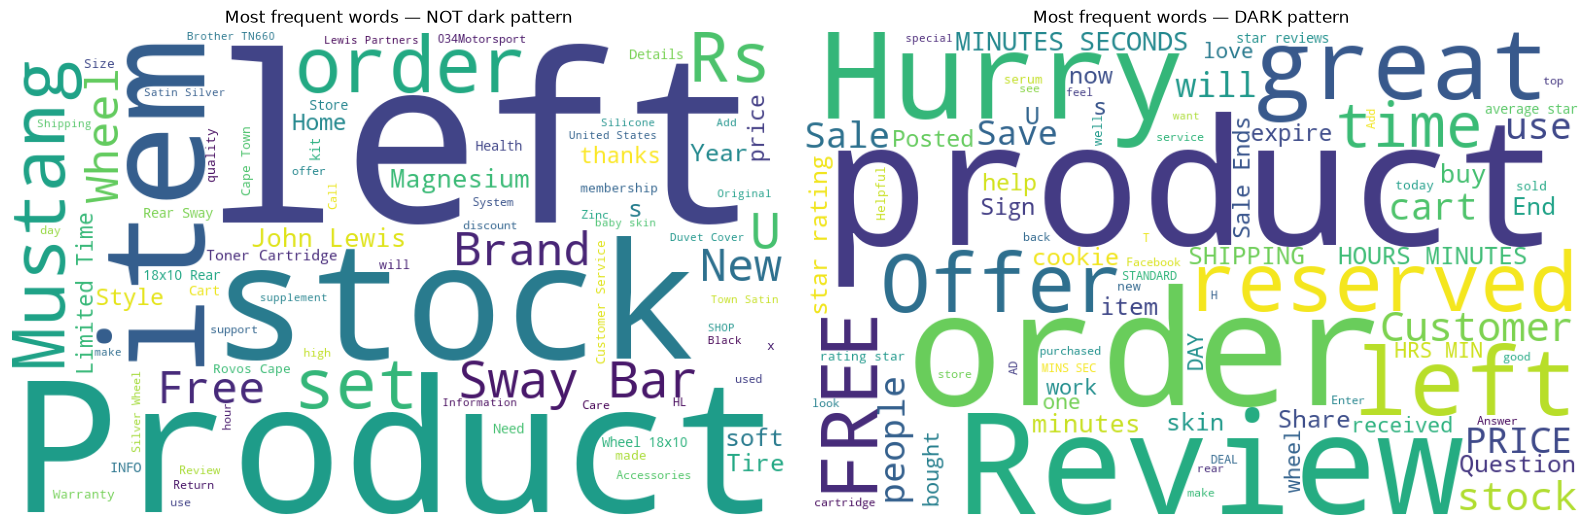

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
not_dark_text = ' '.join(df[df['label']==0]['text'].astype(str))
dark_text = ' '.join(df[df['label']==1]['text'].astype(str))

axes[0].imshow(WordCloud(width=800, height=500, background_color='white', max_words=80).generate(not_dark_text))
axes[0].set_title('Most frequent words — NOT dark pattern')
axes[0].axis('off')

axes[1].imshow(WordCloud(width=800, height=500, background_color='white', max_words=80).generate(dark_text))
axes[1].set_title('Most frequent words — DARK pattern')
axes[1].axis('off')
plt.tight_layout()
plt.show()

## 5. Domain-Specific Cleaning, Duplicate Control & Preprocessing

For this task, **minimal cleaning is safer than generic NLP cleaning**. Words such as *no*, *not*, *without*, numbers, currency symbols and punctuation can carry the manipulation signal. We therefore normalize HTML/URLs/whitespace while preserving most natural-language structure.

A second representation, `dedup_key`, is intentionally more aggressive and is used **only to detect near-duplicate formatting variants before splitting**. This prevents the same template appearing in both train and test and inflating performance.


In [8]:
def normalize_text(text):
    """Light normalization for classical/deep models; preserves negation, digits and punctuation."""
    text = html.unescape(str(text))
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'https?://\S+|www\.\S+', ' URL ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text


def make_dedup_key(text):
    """Normalization used ONLY for duplicate detection, not for training."""
    text = normalize_text(text).lower()
    text = re.sub(r'url', ' ', text)
    text = re.sub(r'[^a-z0-9]+', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()


df['clean_text'] = df['text'].apply(normalize_text)
df['dedup_key'] = df['text'].apply(make_dedup_key)

# Remove exact/formatting duplicates before splitting. If duplicate versions disagree on
# the label, drop the entire conflicting key rather than allowing ambiguous supervision.
label_nunique = df.groupby('dedup_key')['label'].nunique()
conflicting_keys = set(label_nunique[label_nunique > 1].index)
if conflicting_keys:
    print(f'Dropping {len(conflicting_keys)} normalized text keys with conflicting labels.')
    df = df[~df['dedup_key'].isin(conflicting_keys)].copy()

before = len(df)
df = df.drop_duplicates(subset='dedup_key', keep='first').reset_index(drop=True)
print(f'Removed {before - len(df)} duplicate/format-variant rows before splitting.')
print('Remaining rows:', len(df))

df[['text', 'clean_text', 'label']].sample(min(5, len(df)), random_state=SEED)

Dropping 14 normalized text keys with conflicting labels.
Removed 94 duplicate/format-variant rows before splitting.
Remaining rows: 1954


,text,clean_text,label
1617,$139.99,$139.99,0
1731,Sale,Sale,0
976,Stay safe,Stay safe,0
1057,-945,-945,0
307,What's Included:,What's Included:,0


## 6. Leakage-Safe Train / Validation / Test Split

The **test set is locked away until final evaluation**. Hyperparameters, early stopping, architecture/model choice and probability thresholds are selected using only training/CV and validation data.

Default split: **70% train / 15% validation / 15% test** (stratified).


In [9]:
X = df['clean_text']
y = df['label']

# First hold out 30%; then divide that equally into validation and test.
X_train_text, X_temp_text, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val_text, X_test_text, y_val, y_test = train_test_split(
    X_temp_text, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print(f'Train: {len(X_train_text)} | Validation: {len(X_val_text)} | Test: {len(X_test_text)}')
print('Train balance:\n', y_train.value_counts(normalize=True).round(4))
print('Validation balance:\n', y_val.value_counts(normalize=True).round(4))
print('Test balance:\n', y_test.value_counts(normalize=True).round(4))

# Sanity check: normalized text keys must not cross partitions.
train_keys = set(df.loc[X_train_text.index, 'dedup_key'])
val_keys = set(df.loc[X_val_text.index, 'dedup_key'])
test_keys = set(df.loc[X_test_text.index, 'dedup_key'])
assert train_keys.isdisjoint(val_keys)
assert train_keys.isdisjoint(test_keys)
assert val_keys.isdisjoint(test_keys)
print('Leakage check passed: no normalized duplicate key crosses a split.')

classes = np.array([0, 1])
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weight_dict = {int(c): float(w) for c, w in zip(classes, weights)}
print('Class weights:', class_weight_dict)

def choose_threshold(y_true, probabilities, beta=1.0):
    """Choose threshold on validation data only by maximizing F-beta."""
    precision, recall, thresholds = precision_recall_curve(y_true, probabilities)
    thresholds = np.append(thresholds, 1.0)
    beta2 = beta ** 2
    fbeta = (1 + beta2) * precision * recall / (beta2 * precision + recall + 1e-12)
    idx = int(np.nanargmax(fbeta))
    return float(thresholds[idx]), float(fbeta[idx]), float(precision[idx]), float(recall[idx])

Train: 1367 | Validation: 293 | Test: 294
Train balance:
 label
0    0.7666
1    0.2334
Name: proportion, dtype: float64
Validation balance:
 label
0    0.7679
1    0.2321
Name: proportion, dtype: float64
Test balance:
 label
0    0.7653
1    0.2347
Name: proportion, dtype: float64
Leakage check passed: no normalized duplicate key crosses a split.
Class weights: {0: 0.6521946564885496, 1: 2.1426332288401255}


## 7. Tier 1 — Classical ML: TF‑IDF + Logistic Regression / Linear SVM

For short text snippets, classical models with TF‑IDF features are strong, fast, and easy to explain.  
We can see which words or phrases drive a prediction, which is important for a consumer‑protection tool.

We compare three algorithms:
- **Multinomial Naive Bayes** → simple and common for text, but struggles with short phrases.  
- **Logistic Regression** → usually the best linear baseline; gives calibrated probabilities.  
- **Linear SVM** → often slightly stronger on sparse text; raw scores aren’t probabilities, so we calibrate them.

We use `class_weight='balanced'` to handle class imbalance, so the majority class doesn’t dominate.


In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

classical_candidates = {
    'MultinomialNB': Pipeline([
        ('tfidf', TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=2)),
        ('clf', MultinomialNB())]),
    'LogisticRegression': Pipeline([
        ('tfidf', TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=2)),
        ('clf', LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED))]),
    'LinearSVM': Pipeline([
        ('tfidf', TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=2)),
        ('clf', CalibratedClassifierCV(LinearSVC(class_weight='balanced', random_state=SEED), cv=3))])}

cv_rows = []
for name, pipe in classical_candidates.items():
    scores = cross_validate(
        pipe, X_train_text, y_train, cv=cv,
        scoring={'f1':'f1', 'precision':'precision', 'recall':'recall', 'roc_auc':'roc_auc'},
        n_jobs=-1)
    cv_rows.append({
        'Model': name,
        'CV F1': scores['test_f1'].mean(),
        'CV Precision': scores['test_precision'].mean(),
        'CV Recall': scores['test_recall'].mean(),
        'CV ROC-AUC': scores['test_roc_auc'].mean()})

classical_cv = pd.DataFrame(cv_rows).set_index('Model').sort_values('CV F1', ascending=False)
classical_cv.style.format('{:.4f}').background_gradient(cmap='Greens', axis=0)


,CV F1,CV Precision,CV Recall,CV ROC-AUC
Model,,,,
LogisticRegression,0.6004,0.5800,0.6238,0.8315
LinearSVM,0.5228,0.7379,0.4076,0.8258
MultinomialNB,0.4277,0.8332,0.2884,0.8169


### 7.1 Classical model selection and tuning — training/CV only

The best classical family is selected from **cross-validation on the training partition**, not from test-set performance. Hyperparameters are then tuned with CV. The untouched validation set is used only to select an operating threshold.


In [11]:
best_classical_name = classical_cv.index[0]
print('Best classical family by training CV:', best_classical_name)

base_pipe = classical_candidates[best_classical_name]
if best_classical_name == 'LogisticRegression':
    param_grid = {
        'tfidf__ngram_range': [(1,1), (1,2)],
        'clf__C': [0.1, 0.5, 1.0, 2.0, 5.0]}
elif best_classical_name == 'LinearSVM':
    param_grid = {
        'tfidf__ngram_range': [(1,1), (1,2)],
        'clf__estimator__C': [0.1, 0.5, 1.0, 2.0, 5.0]}
else:
    param_grid = {
        'tfidf__ngram_range': [(1,1), (1,2)],
        'clf__alpha': [0.1, 0.5, 1.0, 2.0] }

grid = GridSearchCV(base_pipe, param_grid, scoring='f1', cv=cv, n_jobs=-1)
grid.fit(X_train_text, y_train)
print('Best params:', grid.best_params_)

best_classical_train_model = grid.best_estimator_
val_proba_classical = best_classical_train_model.predict_proba(X_val_text)[:, 1]
CLASSICAL_THRESHOLD, val_f1_classical, val_p_classical, val_r_classical = choose_threshold(
    y_val, val_proba_classical, beta=1.0)
val_pred_classical = (val_proba_classical >= CLASSICAL_THRESHOLD).astype(int)

print(f'Validation threshold: {CLASSICAL_THRESHOLD:.3f}')
print(f'Validation F1={val_f1_classical:.4f}, Precision={val_p_classical:.4f}, Recall={val_r_classical:.4f}')
print(classification_report(y_val, val_pred_classical, target_names=['Not Dark', 'Dark']))


Best classical family by training CV: LogisticRegression
Best params: {'clf__C': 2.0, 'tfidf__ngram_range': (1, 2)}
Validation threshold: 0.443
Validation F1=0.5988, Precision=0.5051, Recall=0.7353
              precision    recall  f1-score   support

    Not Dark       0.91      0.78      0.84       225
        Dark       0.51      0.74      0.60        68

    accuracy                           0.77       293
   macro avg       0.71      0.76      0.72       293
weighted avg       0.81      0.77      0.78       293



### 7.2 Interpretability check — LIME

Before using deep learning, let’s make sure our classical model is focusing on meaningful words.  
LIME helps with this by slightly changing the input text and watching how the prediction shifts.  
It shows which words pushed the decision toward **Dark** or **Not Dark** for a single example.

In [12]:
explainer = LimeTextExplainer(class_names=['Not Dark', 'Dark'])

sample_idx = y_val[y_val == 1].index[0] if (y_val == 1).any() else y_val.index[0]
sample_text = X_val_text.loc[sample_idx]

exp = explainer.explain_instance(sample_text, best_classical_train_model.predict_proba, num_features=8)
print('Example text:', sample_text)
print('True label:', 'Dark' if y_val.loc[sample_idx] == 1 else 'Not Dark')
exp.show_in_notebook(text=True)


Example text: Try Unlimited
True label: Dark


## 8. Tier 2 — Word2Vec + BiLSTM

The classical model only counts words, so it misses word order.  
For example: **"not a great deal"** vs **"a great deal"** look almost the same in bag‑of‑words.

A recurrent model reads words in sequence, which helps catch phrasing tricks often used in dark‑pattern text.

We train our own **Word2Vec embeddings** on the dataset (better for e‑commerce language than generic ones).  
These embeddings go into a **Bidirectional LSTM**:
- **Bidirectional** → looks at context from both left and right.  
- **LSTM** → handles long sequences without losing information (better than a plain RNN).

In [13]:
VOCAB_SIZE = 15000
EMBEDDING_DIM = 64

tokenizer_kb = Tokenizer(num_words=VOCAB_SIZE, oov_token='<OOV>')
tokenizer_kb.fit_on_texts(X_train_text)

X_train_seq = tokenizer_kb.texts_to_sequences(X_train_text)
X_val_seq = tokenizer_kb.texts_to_sequences(X_val_text)
X_test_seq = tokenizer_kb.texts_to_sequences(X_test_text)

seq_lengths = [len(s) for s in X_train_seq]
MAX_LEN = max(int(np.percentile(seq_lengths, 95)), 10)
print(f'Padding length (95th percentile): {MAX_LEN} tokens')

X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding='post', truncating='post')
X_val_pad = pad_sequences(X_val_seq, maxlen=MAX_LEN, padding='post', truncating='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding='post', truncating='post')

actual_vocab_size = min(VOCAB_SIZE, len(tokenizer_kb.word_index) + 1)

# Word2Vec is trained on TRAIN text only.
training_tokens = [re.findall(r"[A-Za-z0-9']+", t.lower()) for t in X_train_text]
# min_count=2 (not 1): a word seen only once has almost no context to learn a
# meaningful vector from, so keeping singletons mostly injects near-random noise
# into the embedding matrix rather than a useful signal.
w2v_model = Word2Vec(
    sentences=training_tokens,
    vector_size=EMBEDDING_DIM, window=5, min_count=2,
    workers=os.cpu_count() or 4, sg=1, epochs=15, seed=SEED
)

embedding_matrix = np.zeros((actual_vocab_size, EMBEDDING_DIM))
for word, idx in tokenizer_kb.word_index.items():
    if idx < actual_vocab_size and word in w2v_model.wv:
        embedding_matrix[idx] = w2v_model.wv[word]

print('Word2Vec vocab:', len(w2v_model.wv))


Padding length (95th percentile): 16 tokens
Word2Vec vocab: 1081


In [14]:
def build_bilstm(vocab_size, embedding_dim, embedding_matrix, max_len):
    model = Sequential([
        Embedding(vocab_size, embedding_dim, weights=[embedding_matrix], trainable=True, mask_zero=True),
        Bidirectional(LSTM(64, dropout=0.3, return_sequences=True)),   # recurrent_dropout=0 keeps cuDNN eligible
        Bidirectional(LSTM(32, dropout=0.3)),
        Dense(32, activation='relu'),
        Dropout(0.4),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=Adam(learning_rate=1e-3), loss='binary_crossentropy', metrics=['accuracy'])
    return model

bilstm_model = build_bilstm(actual_vocab_size, EMBEDDING_DIM, embedding_matrix, MAX_LEN)
bilstm_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ ?                           │         168,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional (Bidirectional)        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional_1 (Bidirectional)      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 168,512 (658.25 KB)

 Trainable params: 168,512 (658.25 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
early_stop = EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6)

history = bilstm_model.fit(
    X_train_pad, y_train,
    validation_data=(X_val_pad, y_val),
    epochs=25,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stop, reduce_lr],
    verbose=1)


Epoch 1/25
43/43 ━━━━━━━━━━━━━━━━━━━━ 27s 108ms/step - accuracy: 0.4067 - loss: 0.6764 - val_accuracy: 0.4881 - val_loss: 0.7254 - learning_rate: 0.0010
Epoch 2/25
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - accuracy: 0.6218 - loss: 0.6558 - val_accuracy: 0.7031 - val_loss: 0.6704 - learning_rate: 0.0010
Epoch 3/25
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.7813 - loss: 0.5659 - val_accuracy: 0.7782 - val_loss: 0.5463 - learning_rate: 0.0010
Epoch 4/25
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 0.8749 - loss: 0.3671 - val_accuracy: 0.7884 - val_loss: 0.5838 - learning_rate: 0.0010
Epoch 5/25
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.9056 - loss: 0.2775 - val_accuracy: 0.7713 - val_loss: 0.7316 - learning_rate: 0.0010
Epoch 6/25
43/43 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.9386 - loss: 0.2117 - val_accuracy: 0.8020 - val_loss: 0.6600 - learning_rate: 5.0000e-04
Epoch 7/25
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 0.9444 - loss: 0.1650 - v

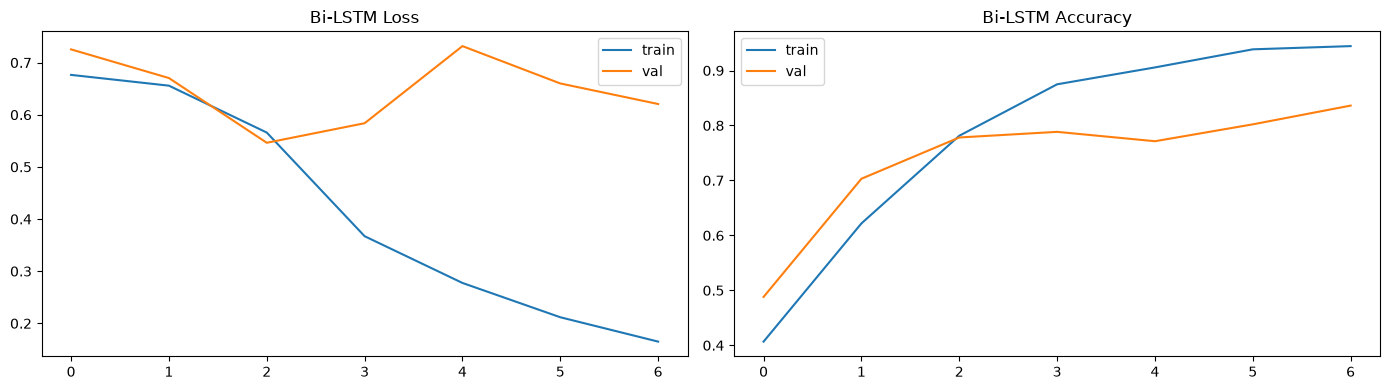

BiLSTM validation threshold: 0.396
              precision    recall  f1-score   support

    Not Dark       0.92      0.74      0.82       225
        Dark       0.47      0.78      0.59        68

    accuracy                           0.75       293
   macro avg       0.70      0.76      0.70       293
weighted avg       0.81      0.75      0.76       293



In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(history.history['loss'], label='train'); axes[0].plot(history.history['val_loss'], label='val')
axes[0].set_title('Bi-LSTM Loss'); axes[0].legend()
axes[1].plot(history.history['accuracy'], label='train'); axes[1].plot(history.history['val_accuracy'], label='val')
axes[1].set_title('Bi-LSTM Accuracy'); axes[1].legend()
plt.tight_layout(); plt.show()

val_proba_lstm = bilstm_model.predict(X_val_pad, verbose=0).ravel()
LSTM_THRESHOLD, val_f1_lstm, val_p_lstm, val_r_lstm = choose_threshold(y_val, val_proba_lstm)
val_pred_lstm = (val_proba_lstm >= LSTM_THRESHOLD).astype(int)
print(f'BiLSTM validation threshold: {LSTM_THRESHOLD:.3f}')
print(classification_report(y_val, val_pred_lstm, target_names=['Not Dark', 'Dark']))


## 9. Tier 3 — DistilBERT (Transformer)

This is the most advanced tier.  
Research shows full BERT/RoBERTa models can reach ~96–97.5% accuracy.  
We use **DistilBERT** instead of full BERT because it is smaller (~60% of the size) but keeps ~97% of BERT’s language power.  
That makes it faster and easier to deploy for real‑time predictions.

**Why it works better than Tier 1 and 2:**  
DistilBERT already understands language from huge pretraining.  
Fine‑tuning it means we only teach it the specific task of spotting manipulative phrasing.  
This is easier than training word embeddings and LSTMs from scratch on our small dataset.

In [17]:
MODEL_NAME = 'distilbert-base-uncased'
MAX_TOKEN_LEN = 64

bert_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Transformers receive minimally normalized natural text, not lemmatized/stop-word-stripped text.
X_train_raw = df.loc[X_train_text.index, 'text'].astype(str).tolist()
X_val_raw = df.loc[X_val_text.index, 'text'].astype(str).tolist()
X_test_raw = df.loc[X_test_text.index, 'text'].astype(str).tolist()

class DarkPatternDataset(torch.utils.data.Dataset):
    def __init__(self, texts, labels, tokenizer, max_len):
        self.encodings = tokenizer(texts, truncation=True, padding=True, max_length=max_len)
        self.labels = list(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {k: torch.tensor(v[idx]) for k, v in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item

train_dataset = DarkPatternDataset(X_train_raw, y_train.tolist(), bert_tokenizer, MAX_TOKEN_LEN)
val_dataset = DarkPatternDataset(X_val_raw, y_val.tolist(), bert_tokenizer, MAX_TOKEN_LEN)
test_dataset = DarkPatternDataset(X_test_raw, y_test.tolist(), bert_tokenizer, MAX_TOKEN_LEN)

print(f'Train examples: {len(train_dataset)} | Validation: {len(val_dataset)} | Test: {len(test_dataset)}')


Train examples: 1367 | Validation: 293 | Test: 294


### Weighted Loss for Class Imbalance

Instead of resampling the dataset, we give the loss function **class weights**.  
This way, the transformer sees every real example once per epoch (no duplicates or dropped rows).  
Mistakes on the minority class are penalized more heavily, helping the model learn balanced predictions.

In [18]:
class WeightedTrainer(Trainer):
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop('labels')
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = torch.nn.CrossEntropyLoss(weight=self.class_weights.to(logits.device))
        loss = loss_fct(logits.view(-1, model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        'accuracy': accuracy_score(labels, preds),
        'precision': precision_score(labels, preds, zero_division=0),
        'recall': recall_score(labels, preds, zero_division=0),
        'f1': f1_score(labels, preds, zero_division=0)}

bert_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)

class_weights_tensor = torch.tensor([class_weight_dict[0], class_weight_dict[1]], dtype=torch.float)

training_args = TrainingArguments( output_dir="./bert_dark_pattern_checkpoints",
                                   num_train_epochs = 6,
                                   per_device_train_batch_size=16,
                                   per_device_eval_batch_size=16,
                                   eval_strategy="epoch",
                                   save_strategy="epoch",
                                   load_best_model_at_end=True,
                                   metric_for_best_model="f1",
                                   greater_is_better=True,
                                   logging_steps=50,
                                   report_to=["none"],          # disable wandb/tensorboard if not needed
                                   logging_first_step=True,     # log at step 0
                                   logging_strategy="steps")    # ensures training loss is logged



trainer = WeightedTrainer( model=bert_model,
                           args=training_args,
                           train_dataset=train_dataset,
                           eval_dataset=val_dataset,
                           compute_metrics=compute_metrics,
                           class_weights=class_weights_tensor,
                           callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])

trainer.train()

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.587455,0.420955,0.791809,0.535354,0.779412,0.634731
2,0.289128,0.588889,0.883959,0.793103,0.676471,0.730159
3,0.170571,0.623400,0.870307,0.692308,0.794118,0.739726
4,0.060529,0.828429,0.887372,0.761194,0.750000,0.755556
5,0.030813,1.009833,0.877133,0.750000,0.705882,0.727273
6,0.013253,0.947470,0.880546,0.746269,0.735294,0.740741


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=516, training_loss=0.18554429649267085, metrics={'train_runtime': 1945.1383, 'train_samples_per_second': 4.217, 'train_steps_per_second': 0.265, 'total_flos': 135812200472064.0, 'train_loss': 0.18554429649267085, 'epoch': 6.0})

In [19]:
# Validation predictions are used for threshold/model selection.
bert_val_output = trainer.predict(val_dataset)
bert_val_logits = bert_val_output.predictions
val_proba_bert = torch.softmax(torch.tensor(bert_val_logits), dim=-1)[:, 1].numpy()
BERT_THRESHOLD, val_f1_bert, val_p_bert, val_r_bert = choose_threshold(y_val, val_proba_bert)
val_pred_bert = (val_proba_bert >= BERT_THRESHOLD).astype(int)

print(f'DistilBERT validation threshold: {BERT_THRESHOLD:.3f}')
print(classification_report(y_val, val_pred_bert, target_names=['Not Dark', 'Dark']))


DistilBERT validation threshold: 0.525
              precision    recall  f1-score   support

    Not Dark       0.93      0.93      0.93       225
        Dark       0.77      0.75      0.76        68

    accuracy                           0.89       293
   macro avg       0.85      0.84      0.85       293
weighted avg       0.89      0.89      0.89       293



## 10. Model Selection on Validation Data

We keep the test set untouched until the end.  
The deployment model is chosen based on **validation F1 score**.  
If DistilBERT is only slightly better, we prefer the lighter classical model for efficiency.  
Once the choice is locked, all models are run once on the test set to build the final comparison table.


In [20]:
validation_comparison = pd.DataFrame({
    'TF-IDF + ' + best_classical_name: {
        'Precision': precision_score(y_val, val_pred_classical, zero_division=0),
        'Recall': recall_score(y_val, val_pred_classical, zero_division=0),
        'F1-score': f1_score(y_val, val_pred_classical, zero_division=0),
        'PR-AUC': average_precision_score(y_val, val_proba_classical),
        'Threshold': CLASSICAL_THRESHOLD
    },
    'Word2Vec + Bi-LSTM': {
        'Precision': precision_score(y_val, val_pred_lstm, zero_division=0),
        'Recall': recall_score(y_val, val_pred_lstm, zero_division=0),
        'F1-score': f1_score(y_val, val_pred_lstm, zero_division=0),
        'PR-AUC': average_precision_score(y_val, val_proba_lstm),
        'Threshold': LSTM_THRESHOLD
    },
    'Fine-tuned DistilBERT': {
        'Precision': precision_score(y_val, val_pred_bert, zero_division=0),
        'Recall': recall_score(y_val, val_pred_bert, zero_division=0),
        'F1-score': f1_score(y_val, val_pred_bert, zero_division=0),
        'PR-AUC': average_precision_score(y_val, val_proba_bert),
        'Threshold': BERT_THRESHOLD
    }
}).T

validation_comparison.style.format('{:.4f}').background_gradient(cmap='Greens', axis=0)


,Precision,Recall,F1-score,PR-AUC,Threshold
TF-IDF + LogisticRegression,0.5051,0.7353,0.5988,0.5978,0.4425
Word2Vec + Bi-LSTM,0.4732,0.7794,0.5889,0.5917,0.3961
Fine-tuned DistilBERT,0.7727,0.7500,0.7612,0.7604,0.5251


In [21]:
DEPLOY_LATENCY_BUDGET = 'low'  # low = prefer simpler model when performance is close
f1_gap = validation_comparison.loc['Fine-tuned DistilBERT', 'F1-score'] - validation_comparison.loc['TF-IDF + ' + best_classical_name, 'F1-score']

if DEPLOY_LATENCY_BUDGET == 'low' and f1_gap < 0.03:
    DEPLOY_MODEL = 'classical'
    DEPLOY_THRESHOLD = CLASSICAL_THRESHOLD
    print(f'Validation F1 gap ({f1_gap:.3f}) is small -> deploying the lighter classical model.')
else:
    DEPLOY_MODEL = 'bert'
    DEPLOY_THRESHOLD = BERT_THRESHOLD
    print(f'Validation F1 gap ({f1_gap:.3f}) justifies DistilBERT -> deploying the transformer.')

print('Locked deployment decision:', DEPLOY_MODEL, '| threshold:', round(DEPLOY_THRESHOLD, 3))


Validation F1 gap (0.162) justifies DistilBERT -> deploying the transformer.
Locked deployment decision: bert | threshold: 0.525


### Final Test Evaluation

This is the **first time** we use the test labels for reporting.  
No hyperparameters, thresholds, or model choices should be changed after seeing these results.  
Once locked, we run all models on the test set one time to create the final comparison table.


In [22]:
# Classical: refit selected/tuned pipeline on train+validation AFTER all choices are locked.
X_trainval_text = pd.concat([X_train_text, X_val_text])
y_trainval = pd.concat([y_train, y_val])
final_classical_pipeline = clone(grid.best_estimator_)
final_classical_pipeline.fit(X_trainval_text, y_trainval)
y_proba_best = final_classical_pipeline.predict_proba(X_test_text)[:, 1]
y_pred_best = (y_proba_best >= CLASSICAL_THRESHOLD).astype(int)

# BiLSTM: final trained instance is the validation-selected checkpoint from early stopping.
y_proba_lstm = bilstm_model.predict(X_test_pad, verbose=0).ravel()
y_pred_lstm = (y_proba_lstm >= LSTM_THRESHOLD).astype(int)

# DistilBERT: Trainer already restored the best validation checkpoint.
bert_test_output = trainer.predict(test_dataset)
bert_test_logits = bert_test_output.predictions
y_proba_bert = torch.softmax(torch.tensor(bert_test_logits), dim=-1)[:, 1].numpy()
y_pred_bert = (y_proba_bert >= BERT_THRESHOLD).astype(int)

comparison = pd.DataFrame({
    'TF-IDF + ' + best_classical_name: {
        'Accuracy': accuracy_score(y_test, y_pred_best),
        'Precision': precision_score(y_test, y_pred_best, zero_division=0),
        'Recall': recall_score(y_test, y_pred_best, zero_division=0),
        'F1-score': f1_score(y_test, y_pred_best, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_proba_best),
        'PR-AUC': average_precision_score(y_test, y_proba_best)
    },
    'Word2Vec + Bi-LSTM': {
        'Accuracy': accuracy_score(y_test, y_pred_lstm),
        'Precision': precision_score(y_test, y_pred_lstm, zero_division=0),
        'Recall': recall_score(y_test, y_pred_lstm, zero_division=0),
        'F1-score': f1_score(y_test, y_pred_lstm, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_proba_lstm),
        'PR-AUC': average_precision_score(y_test, y_proba_lstm)
    },
    'Fine-tuned DistilBERT': {
        'Accuracy': accuracy_score(y_test, y_pred_bert),
        'Precision': precision_score(y_test, y_pred_bert, zero_division=0),
        'Recall': recall_score(y_test, y_pred_bert, zero_division=0),
        'F1-score': f1_score(y_test, y_pred_bert, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_proba_bert),
        'PR-AUC': average_precision_score(y_test, y_proba_bert)
    }
}).T

display(comparison.style.format('{:.4f}').background_gradient(cmap='Greens', axis=0))

for name, pred in [
    ('Classical', y_pred_best), ('BiLSTM', y_pred_lstm), ('DistilBERT', y_pred_bert)
]:
    print('\n---', name, '---')
    print(classification_report(y_test, pred, target_names=['Not Dark', 'Dark']))


,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
TF-IDF + LogisticRegression,0.8095,0.5699,0.7681,0.6543,0.8808,0.7206
Word2Vec + Bi-LSTM,0.7789,0.5189,0.7971,0.6286,0.8634,0.6724
Fine-tuned DistilBERT,0.8810,0.7833,0.6812,0.7287,0.9181,0.7838



--- Classical ---
              precision    recall  f1-score   support

    Not Dark       0.92      0.82      0.87       225
        Dark       0.57      0.77      0.65        69

    accuracy                           0.81       294
   macro avg       0.75      0.80      0.76       294
weighted avg       0.84      0.81      0.82       294


--- BiLSTM ---
              precision    recall  f1-score   support

    Not Dark       0.93      0.77      0.84       225
        Dark       0.52      0.80      0.63        69

    accuracy                           0.78       294
   macro avg       0.72      0.79      0.74       294
weighted avg       0.83      0.78      0.79       294


--- DistilBERT ---
              precision    recall  f1-score   support

    Not Dark       0.91      0.94      0.92       225
        Dark       0.78      0.68      0.73        69

    accuracy                           0.88       294
   macro avg       0.84      0.81      0.83       294
weighted avg       

### Statistical Robustness — Bootstrap Confidence Intervals

The test set is just one sample, so a raw F1 or PR‑AUC gap can look bigger than it really is.  
To check reliability, we use **bootstrap resampling** (sample with replacement, 1000 times).  
This gives a 95% confidence interval for each model’s F1 and PR‑AUC.  
These intervals show whether the performance difference is truly meaningful, not just a single point estimate.

In [23]:
N_BOOTSTRAP = 1000
ALPHA = 0.05
rng = np.random.RandomState(SEED)


def bootstrap_ci(y_true, y_proba, y_pred, n_boot=N_BOOTSTRAP, alpha=ALPHA):
    y_true = np.asarray(y_true)
    y_proba = np.asarray(y_proba)
    y_pred = np.asarray(y_pred)
    n = len(y_true)
    idx_all = np.arange(n)
    f1_samples, prauc_samples = [], []
    for _ in range(n_boot):
        idx = rng.choice(idx_all, size=n, replace=True)
        if len(np.unique(y_true[idx])) < 2:
            continue  # degenerate resample with only one class present
        f1_samples.append(f1_score(y_true[idx], y_pred[idx], zero_division=0))
        prauc_samples.append(average_precision_score(y_true[idx], y_proba[idx]))

    def summarize(samples):
        lo, hi = np.percentile(samples, [100 * alpha / 2, 100 * (1 - alpha / 2)])
        return float(np.mean(samples)), float(lo), float(hi)

    return summarize(f1_samples), summarize(prauc_samples)


bootstrap_rows = []
for name, proba, pred in [
    ('TF-IDF + ' + best_classical_name, y_proba_best, y_pred_best),
    ('Word2Vec + Bi-LSTM', y_proba_lstm, y_pred_lstm),
    ('Fine-tuned DistilBERT', y_proba_bert, y_pred_bert),
]:
    (f1_mean, f1_lo, f1_hi), (pr_mean, pr_lo, pr_hi) = bootstrap_ci(y_test, proba, pred)
    bootstrap_rows.append({
        'Model': name,
        'F1 (mean)': f1_mean, 'F1 95% CI': f'[{f1_lo:.3f}, {f1_hi:.3f}]',
        'PR-AUC (mean)': pr_mean, 'PR-AUC 95% CI': f'[{pr_lo:.3f}, {pr_hi:.3f}]',
    })

bootstrap_df = pd.DataFrame(bootstrap_rows).set_index('Model')
print(f'Test set size: {len(y_test)} rows — treat any gap smaller than the CI width as noise, '
      f'not a real difference between models.')
bootstrap_df

Test set size: 294 rows — treat any gap smaller than the CI width as noise, not a real difference between models.


,F1 (mean),F1 95% CI,PR-AUC (mean),PR-AUC 95% CI
Model,,,,
TF-IDF + LogisticRegression,0.652754,"[0.565, 0.736]",0.723508,"[0.613, 0.816]"
Word2Vec + Bi-LSTM,0.627472,"[0.548, 0.711]",0.675116,"[0.565, 0.780]"
Fine-tuned DistilBERT,0.730033,"[0.638, 0.812]",0.789116,"[0.689, 0.884]"


### Qualitative Error Analysis — False Positives & False Negatives

Metrics alone don’t explain *why* a model is wrong.  
We look at the test examples the deployment model misclassified — especially the ones it was most confident about but still wrong.  
This helps us see common failure cases, like:
- Negation flipping the meaning (e.g. “not urgent”)  
- Borderline phrasing that is tricky to classify  
- Possible labeling mistakes in the dataset  

By inspecting these examples directly, we understand the model’s weaknesses instead of just guessing from numbers.

In [24]:
deploy_test_proba = y_proba_best if DEPLOY_MODEL == 'classical' else y_proba_bert
deploy_test_pred = y_pred_best if DEPLOY_MODEL == 'classical' else y_pred_bert

error_df = pd.DataFrame({
    'text': df.loc[X_test_text.index, 'text'].values,
    'true_label': y_test.values,
    'pred_label': deploy_test_pred,
    'dark_probability': deploy_test_proba,
})

false_positives = error_df[(error_df.true_label == 0) & (error_df.pred_label == 1)] \
    .sort_values('dark_probability', ascending=False)
false_negatives = error_df[(error_df.true_label == 1) & (error_df.pred_label == 0)] \
    .sort_values('dark_probability')

print(f'Deployment model: {DEPLOY_MODEL} | False positives: {len(false_positives)} '
      f'| False negatives: {len(false_negatives)} (of {len(error_df)} test rows)')

print('\n--- Most confident FALSE POSITIVES (predicted Dark, actually Not Dark) ---')
print(false_positives.head(10)[['text', 'dark_probability']].to_string(index=False))

print('\n--- Most confident FALSE NEGATIVES (predicted Not Dark, actually Dark) ---')
print(false_negatives.head(10)[['text', 'dark_probability']].to_string(index=False))

Deployment model: bert | False positives: 13 | False negatives: 22 (of 294 test rows)

--- Most confident FALSE POSITIVES (predicted Dark, actually Not Dark) ---
                                                                 text  dark_probability
jennifer just bought Rainbow Moonstone Healing Heartabout 6 hours ago          0.995282
                                         OFFER ENDS: 09h: 09m: 55s: 0          0.994437
                                                    WE ALSO RECOMMEND          0.994077
                                             Other delightful options          0.990146
                                               Reviews & Testimonials          0.975103
                                            12 recently purchased it.          0.951059
                                                 1 2 3 4 5 6 7 8 9 10          0.900914
                     Sorry, this is out of stock. You just missed it.          0.891336
                                              

## 10. Final Diagnostics & Saving Deployment Artifacts

The API/UI act as **binary detectors**.  
They report **“potential dark‑pattern language”** because text alone cannot confirm if claims about scarcity, urgency, or social proof are true or intentionally deceptive.  
This wording keeps the tool cautious and transparent.

At this stage, we also save the final deployment artifacts (model, thresholds, configs) so the chosen detector can be served consistently in production.

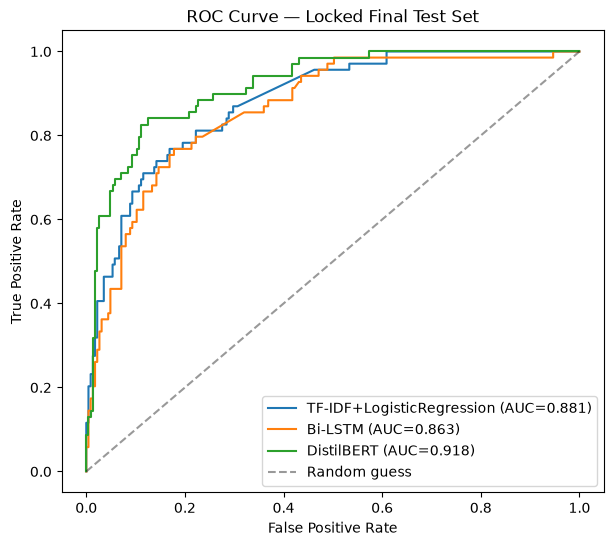

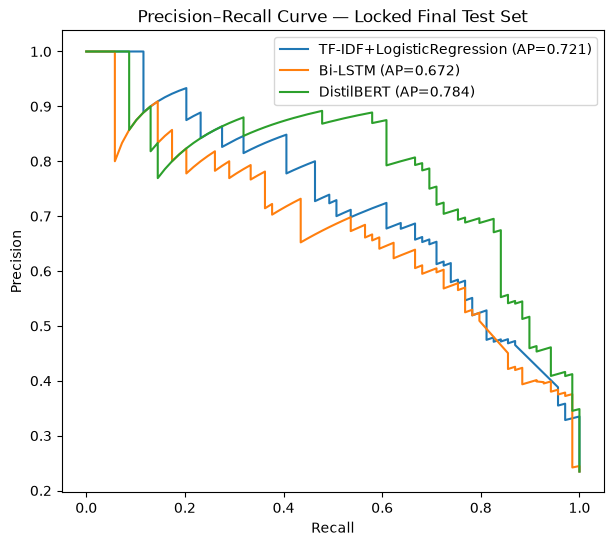

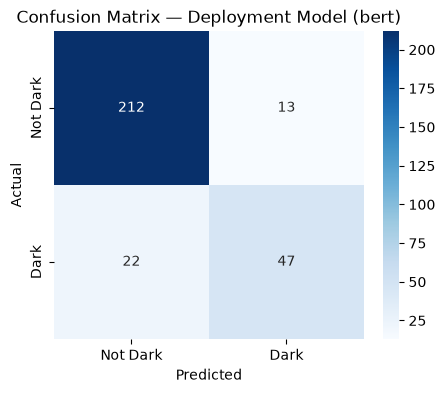

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved deployment artifacts to ./model_artifacts/
{
  "recommended_model": "bert",
  "label_names": [
    "Not Dark Pattern",
    "Potential Dark Pattern"
  ],
  "max_token_len": 64,
  "thresholds": {
    "classical": 0.4425046777476985,
    "bert": 0.525092601776123
  },
  "task": "binary_text_risk_screening",
  "limitation": "Text-only screening cannot verify whether a claim is factually false or intentionally manipulative."
}


In [25]:
# Final ROC + Precision-Recall diagnostics.
plt.figure(figsize=(7, 6))
for name, proba in [
    ('TF-IDF+' + best_classical_name, y_proba_best),
    ('Bi-LSTM', y_proba_lstm),
    ('DistilBERT', y_proba_bert)
]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test, proba):.3f})')
plt.plot([0,1],[0,1],'k--',alpha=0.4, label='Random guess')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curve — Locked Final Test Set')
plt.legend(); plt.show()

plt.figure(figsize=(7, 6))
for name, proba in [
    ('TF-IDF+' + best_classical_name, y_proba_best),
    ('Bi-LSTM', y_proba_lstm),
    ('DistilBERT', y_proba_bert)
]:
    p, r, _ = precision_recall_curve(y_test, proba)
    plt.plot(r, p, label=f'{name} (AP={average_precision_score(y_test, proba):.3f})')
plt.xlabel('Recall'); plt.ylabel('Precision')
plt.title('Precision–Recall Curve — Locked Final Test Set')
plt.legend(); plt.show()

# Confusion matrix for the chosen deployment model.
if DEPLOY_MODEL == 'classical':
    deploy_pred_test = y_pred_best
else:
    deploy_pred_test = y_pred_bert
cm = confusion_matrix(y_test, deploy_pred_test)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Not Dark','Dark'], yticklabels=['Not Dark','Dark'])
plt.title(f'Confusion Matrix — Deployment Model ({DEPLOY_MODEL})')
plt.ylabel('Actual'); plt.xlabel('Predicted'); plt.show()

os.makedirs('model_artifacts', exist_ok=True)

# Save only the deployable classical pipeline and DistilBERT artifacts. The serving code lazy-loads
# the requested/default model, so both may exist on disk without both consuming RAM at startup.
with open('model_artifacts/classical_pipeline.pkl', 'wb') as f:
    pickle.dump(final_classical_pipeline, f)
trainer.save_model('model_artifacts/distilbert_dark_pattern')
bert_tokenizer.save_pretrained('model_artifacts/distilbert_dark_pattern')

metadata = {
    'recommended_model': DEPLOY_MODEL,
    'label_names': ['Not Dark Pattern', 'Potential Dark Pattern'],
    'max_token_len': MAX_TOKEN_LEN,
    'thresholds': {
        'classical': float(CLASSICAL_THRESHOLD),
        'bert': float(BERT_THRESHOLD)
    },
    'task': 'binary_text_risk_screening',
    'limitation': 'Text-only screening cannot verify whether a claim is factually false or intentionally manipulative.'
}
with open('model_artifacts/metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)

print('Saved deployment artifacts to ./model_artifacts/')
print(json.dumps(metadata, indent=2))


## 11. Inference Function

At inference time, we use the same threshold chosen during validation.  
The model shows a confidence score (its probability output).  
This should be described as a **model score**, not a guaranteed real‑world probability, unless extra calibration is applied.

In [26]:
def predict_dark_pattern(text, model_choice=None):
    model_choice = model_choice or DEPLOY_MODEL
    cleaned = normalize_text(text)

    if model_choice == 'classical':
        dark_proba = float(final_classical_pipeline.predict_proba([cleaned])[0, 1])
        threshold = CLASSICAL_THRESHOLD
    else:
        inputs = bert_tokenizer(str(text), truncation=True, padding=True, max_length=MAX_TOKEN_LEN, return_tensors='pt')
        with torch.no_grad():
            logits = bert_model(**inputs).logits
        dark_proba = float(torch.softmax(logits, dim=-1)[0, 1])
        threshold = BERT_THRESHOLD

    is_dark = dark_proba >= threshold
    label = 'Potential Dark Pattern' if is_dark else 'Not Dark Pattern'
    decision_confidence = dark_proba if is_dark else 1 - dark_proba
    return label, decision_confidence, dark_proba

sample_snippets = [
    'Only 2 rooms left at this price!',
    'This t-shirt is made from 100% organic cotton.',
    '5 other people have this in their cart right now',
    'Free shipping on orders over $50.'
]

for s in sample_snippets:
    label, conf, dark_prob = predict_dark_pattern(s)
    print(f'[{label} | decision confidence={conf:.2%} | P(dark)={dark_prob:.2%}] {s}')


[Not Dark Pattern | decision confidence=99.11% | P(dark)=0.89%] Only 2 rooms left at this price!
[Not Dark Pattern | decision confidence=99.84% | P(dark)=0.16%] This t-shirt is made from 100% organic cotton.
[Potential Dark Pattern | decision confidence=99.63% | P(dark)=99.63%] 5 other people have this in their cart right now
[Not Dark Pattern | decision confidence=99.32% | P(dark)=0.68%] Free shipping on orders over $50.


## 11. Conclusion & Deployment

- Unknown labels are checked and cleaned.  
- Duplicate templates are removed before splitting.  
- Train / validation / test sets are kept separate.  
- Classical models use cross‑validation on training data.  
- BiLSTM and DistilBERT use validation data for early stopping (never test data).  
- Probability thresholds are chosen on validation data.  
- Deployment choice is locked before test reporting.  
- The API/UI lazy‑load models to save memory.  
- The UI supports both single snippets and multi‑line text.  
- Outputs are phrased as **“potential dark‑pattern language”**, since text alone cannot prove deception.

### 11.1 Next Extension
If the dataset has a reliable `category` field with enough examples per class, train a **multiclass category classifier** (e.g. scarcity, urgency, social proof, confirm‑shaming).  
Do not claim category detection in the app until this model is separately trained and evaluated.
